In [ ]:
print("PCCML508 - DEEP LEARNING LAB")

PCCML508 - DEEP LEARNING LAB



--- Simple Linear Regression ---
MSE: 6.1 , R2: 0.8


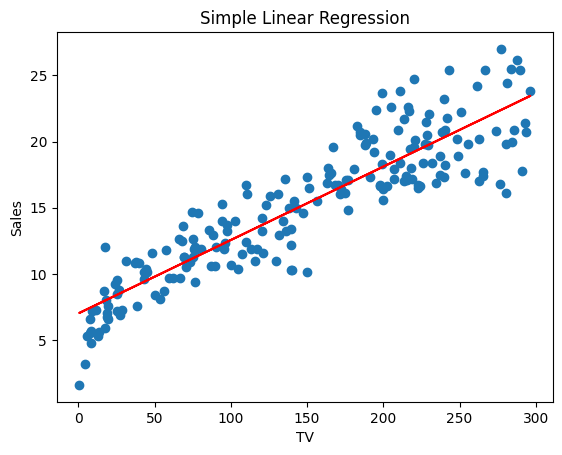


--- Multiple Linear Regression ---
MSE: 2.91 , R2: 0.91


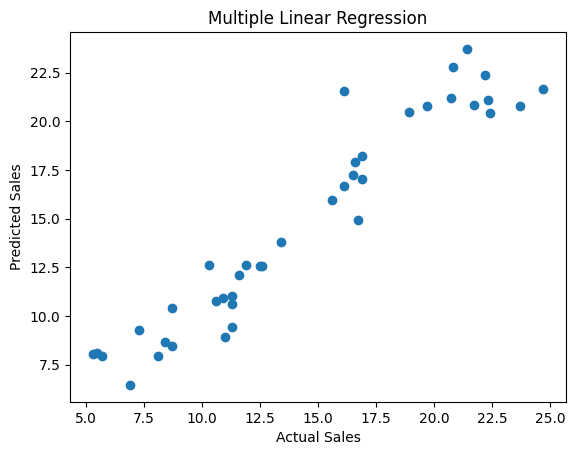


--- Polynomial Regression ---
MSE: 5.68 , R2: 0.82


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


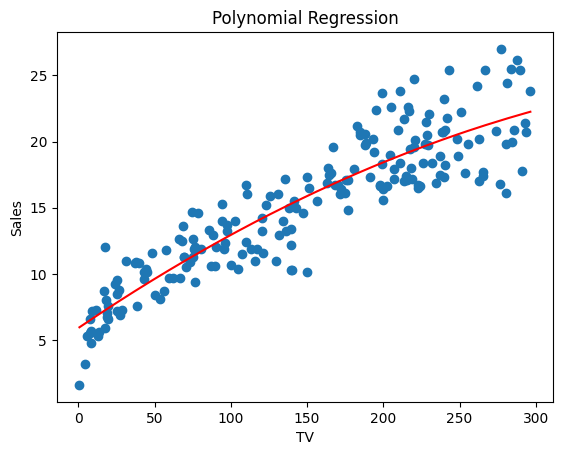

In [ ]:
#EXP1 - REGRESSION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

data=pd.read_csv("Regression.csv")

# Simple Linear Regression
X,y=data[['TV']],data['Sales']
Xt,Xv,yt,yv=train_test_split(X,y,test_size=.2,random_state=42)
m=LinearRegression().fit(Xt,yt)
p=m.predict(Xv)
print("\n--- Simple Linear Regression ---")
print("MSE:",round(mean_squared_error(yv,p),2),", R2:",round(r2_score(yv,p),2))
plt.scatter(X,y);plt.plot(X,m.predict(X), color='red');plt.title("Simple Linear Regression")
plt.xlabel("TV");plt.ylabel("Sales");plt.show()

# Multiple Linear Regression
X,y=data[['TV','Radio','Newspaper']],data['Sales']
Xt,Xv,yt,yv=train_test_split(X,y,test_size=.2,random_state=42)
m=LinearRegression().fit(Xt,yt);p=m.predict(Xv)
print("\n--- Multiple Linear Regression ---")
print("MSE:",round(mean_squared_error(yv,p),2),", R2:",round(r2_score(yv,p),2))
plt.scatter(yv,p);plt.title("Multiple Linear Regression")
plt.xlabel("Actual Sales");plt.ylabel("Predicted Sales");plt.show()

# Polynomial Regression
X,y=data[['TV']],data['Sales']
poly=PolynomialFeatures(2)
Xp=poly.fit_transform(X)
Xt,Xv,yt,yv=train_test_split(Xp,y,test_size=.2,random_state=42)
m=LinearRegression().fit(Xt,yt);p=m.predict(Xv)
print("\n--- Polynomial Regression ---")
print("MSE:",round(mean_squared_error(yv,p),2),", R2:",round(r2_score(yv,p),2))
xs=np.sort(X,axis=0)
plt.scatter(X,y);plt.plot(xs,m.predict(poly.transform(xs)), color='red')
plt.title("Polynomial Regression");plt.xlabel("TV");plt.ylabel("Sales");plt.show()

In [ ]:
#EXP2 - KNN CLASSIFIER
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix

X,y=make_classification(n_samples=200,n_features=2,n_informative=2,
                        n_redundant=0,n_clusters_per_class=1,random_state=42)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42)

model=KNeighborsClassifier(n_neighbors=5)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

print("Accuracy :",round(accuracy_score(y_test,y_pred)*100,2),"%")
print("Precision:",round(precision_score(y_test,y_pred)*100,2),"%")
print("Recall   :",round(recall_score(y_test,y_pred)*100,2),"%")
print("Confusion Matrix:\n",confusion_matrix(y_test,y_pred))

Accuracy : 90.0 %
Precision: 82.61 %
Recall   : 95.0 %
Confusion Matrix:
 [[26  4]
 [ 1 19]]


In [ ]:
#EXP3 - NAIVE BAYES CLASSIFIER
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score,precision_score,recall_score

data=load_iris()
X,y=data.data,data.target

Xt,Xv,yt,yv=train_test_split(X,y,test_size=.2,
                              random_state=42,stratify=y)

model=GaussianNB().fit(Xt,yt)
p=model.predict(Xv)

print("Accuracy :",round(accuracy_score(yv,p)*100,2),"%")
print("Precision:",round(precision_score(yv,p,average="weighted")*100,2),"%")
print("Recall   :",round(recall_score(yv,p,average="weighted")*100,2),"%")

Accuracy : 96.67 %
Precision: 96.97 %
Recall   : 96.67 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


Prediction: No


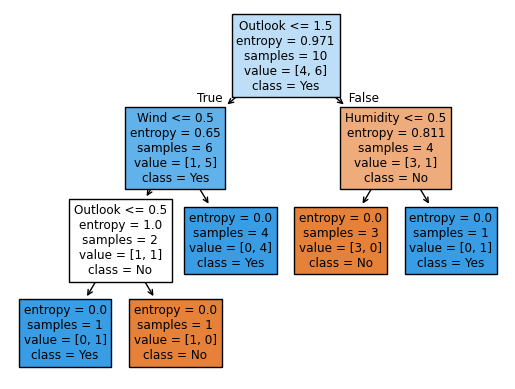

In [ ]:
#EXP4 - DECISION TREE CLASSIFIER
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier,plot_tree
import matplotlib.pyplot as plt

data={
'Outlook':['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain'],
'Temperature':['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild'],
'Humidity':['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal'],
'Wind':['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak'],
'PlayTennis':['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes']}

df=pd.DataFrame(data)
encoders={}
for c in df.columns:
    encoders[c]=LabelEncoder()
    df[c]=encoders[c].fit_transform(df[c])

X=df.drop('PlayTennis',axis=1)
y=df.PlayTennis

tree=DecisionTreeClassifier(criterion='entropy',random_state=42).fit(X,y)

new={'Outlook':['Rain'],'Temperature':['Cool'],'Humidity':['High'],'Wind':['Strong']}
sample=[encoders[c].transform(new[c])[0] for c in X.columns]
result=encoders['PlayTennis'].inverse_transform(tree.predict([sample]))[0]

print("Prediction:",result)

plot_tree(tree,feature_names=X.columns,class_names=['No','Yes'],filled=True)
plt.show()

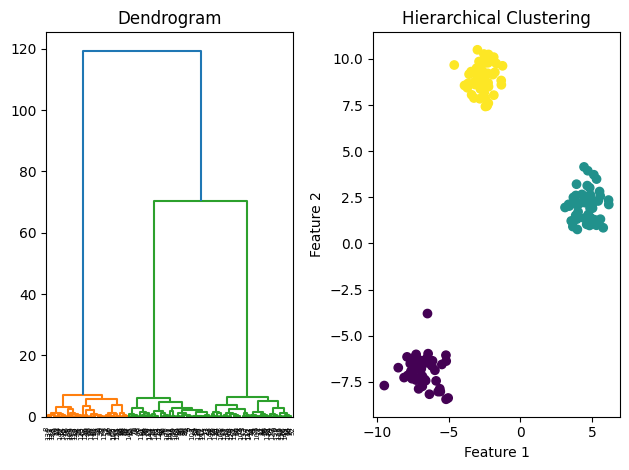

In [ ]:
#EXP5 - HIERARCHICAL AGGLOMERATIVE CLUSTERING
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch

X,_=make_blobs(n_samples=150,centers=3,cluster_std=.8,random_state=42)

plt.figure()
plt.subplot(1,2,1)
sch.dendrogram(sch.linkage(X,method='ward'))
plt.title("Dendrogram")

model=AgglomerativeClustering(n_clusters=3,linkage='ward')
labels=model.fit_predict(X)

plt.subplot(1,2,2)
plt.scatter(X[:,0],X[:,1],c=labels,cmap='viridis')
plt.title("Hierarchical Clustering")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.tight_layout(); plt.show()

K = 4
Inertia: 203.89


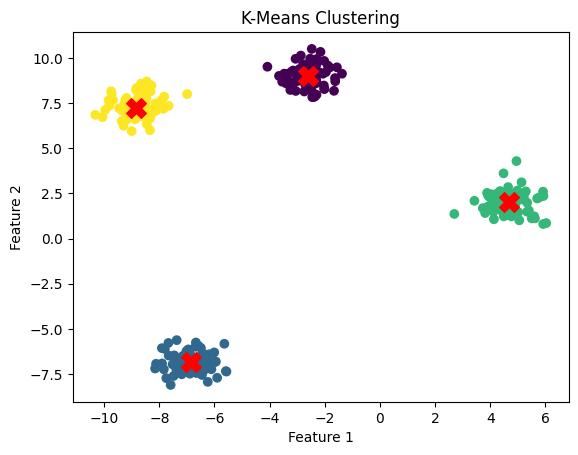

In [ ]:
#EXP6 - K MEANS CLUSTERING
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X,_=make_blobs(n_samples=300,centers=4,cluster_std=.6,random_state=42)

k=4
model=KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
labels=model.fit_predict(X)
centroids=model.cluster_centers_

print("K =",k)
print("Inertia:",round(model.inertia_,2))

plt.scatter(X[:,0],X[:,1],c=labels,cmap='viridis')
plt.scatter(centroids[:,0],centroids[:,1],c='red',marker='X',s=200)
plt.title("K-Means Clustering")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.show()

Epoch 1000: Loss=0.2924
Epoch 2000: Loss=0.2904
Epoch 3000: Loss=0.2895
Epoch 4000: Loss=0.2890
Epoch 5000: Loss=0.2886
Accuracy: 86.0 %


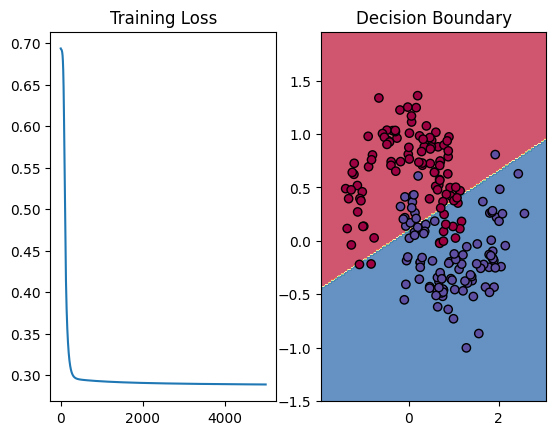

In [ ]:
#EXP7 - ARTIFICIAL NEURAL NETWORK
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X,y=make_moons(n_samples=1000,noise=.2,random_state=42)
y=y.reshape(-1,1)
Xt,Xv,yt,yv=train_test_split(X,y,test_size=.2,random_state=42)

def sigmoid(x): return 1/(1+np.exp(-x))
def dsigmoid(x): return x*(1-x)

class NeuralNetwork:
    def __init__(self,inp,hid,out,lr=.5):
        np.random.seed(42);self.lr=lr
        self.W1=np.random.randn(inp,hid)*.1
        self.b1=np.zeros((1,hid))
        self.W2=np.random.randn(hid,out)*.1
        self.b2=np.zeros((1,out))

    def forward(self,X):
        self.A1=sigmoid(X@self.W1+self.b1)
        self.A2=sigmoid(self.A1@self.W2+self.b2)
        return self.A2

    def backward(self,X,y):
        m=len(X);d2=self.A2-y
        dW2=self.A1.T@d2/m
        db2=np.sum(d2,axis=0,keepdims=True)/m
        d1=(d2@self.W2.T)*dsigmoid(self.A1)
        dW1=X.T@d1/m
        db1=np.sum(d1,axis=0,keepdims=True)/m
        self.W2-=self.lr*dW2;self.b2-=self.lr*db2
        self.W1-=self.lr*dW1;self.b1-=self.lr*db1

    def train(self,X,y,epochs):
        history=[]
        for i in range(epochs):
            p=self.forward(X)
            loss=-np.mean(y*np.log(p+1e-8)+(1-y)*np.log(1-p+1e-8))
            history.append(loss);self.backward(X,y)
            if (i+1)%1000==0: print(f"Epoch {i+1}: Loss={loss:.4f}")
        return history

    def predict(self,X):
        return (self.forward(X)>=.5).astype(int)

nn=NeuralNetwork(2,4,1)
history=nn.train(Xt,yt,5000)
p=nn.predict(Xv)
print("Accuracy:",round(accuracy_score(yv,p)*100,2),"%")

plt.subplot(1,2,1)
plt.plot(history)
plt.title("Training Loss")

plt.subplot(1,2,2)
x1,x2=X[:,0].min()-.5,X[:,0].max()+.5
y1,y2=X[:,1].min()-.5,X[:,1].max()+.5
xx,yy=np.meshgrid(np.arange(x1,x2,.02),np.arange(y1,y2,.02))
Z=nn.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
plt.contourf(xx,yy,Z,alpha=.8,cmap=plt.cm.Spectral)
plt.scatter(Xv[:,0],Xv[:,1],c=yv.ravel(),edgecolors='k',cmap=plt.cm.Spectral)
plt.title("Decision Boundary")
plt.show()

100%|██████████| 170M/170M [48:39<00:00, 58.4kB/s]


Epoch 1: Accuracy=45.24%
Epoch 2: Accuracy=48.08%
Epoch 3: Accuracy=50.84%
Epoch 4: Accuracy=52.33%
Epoch 5: Accuracy=52.32%
Epoch 6: Accuracy=52.26%
Epoch 7: Accuracy=53.66%
Epoch 1: Accuracy=40.60%
Epoch 2: Accuracy=42.55%
Epoch 3: Accuracy=44.87%
Epoch 4: Accuracy=46.50%
Epoch 5: Accuracy=46.56%
Epoch 6: Accuracy=46.70%
Epoch 7: Accuracy=48.36%


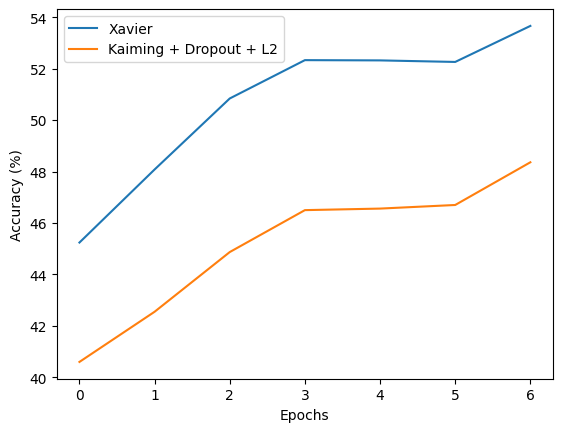

In [ ]:
#EXP8 - FEED FORWARD NETWORK
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

t=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((.5,.5,.5),(.5,.5,.5))
])

trainset=torchvision.datasets.CIFAR10("./data",True,download=True,transform=t)
testset=torchvision.datasets.CIFAR10("./data",False,download=True,transform=t)

trainloader=torch.utils.data.DataLoader(trainset,batch_size=64,shuffle=True)
testloader=torch.utils.data.DataLoader(testset,batch_size=64)

class FFNN(nn.Module):
    def __init__(self,drop=False,init="xavier"):
        super().__init__()
        self.fc=nn.Sequential(
            nn.Flatten(),nn.Linear(3072,1024),nn.ReLU(),
            nn.Dropout(.3) if drop else nn.Identity(),
            nn.Linear(1024,512),nn.ReLU(),
            nn.Dropout(.3) if drop else nn.Identity(),
            nn.Linear(512,256),nn.ReLU(),
            nn.Dropout(.3) if drop else nn.Identity(),
            nn.Linear(256,10))
        for l in self.modules():
            if isinstance(l,nn.Linear):
                if init=="xavier": nn.init.xavier_normal_(l.weight)
                else: nn.init.kaiming_normal_(l.weight,nonlinearity="relu")
                nn.init.zeros_(l.bias)

    def forward(self,x):
        return self.fc(x)

def train(model,opt):
    acc=[]
    model.to(device)
    for e in range(7):
        model.train()
        for x,y in trainloader:
            x,y=x.to(device),y.to(device)
            opt.zero_grad()
            loss=nn.CrossEntropyLoss()(model(x),y)
            loss.backward()
            opt.step()

        model.eval(); correct=total=0
        with torch.no_grad():
            for x,y in testloader:
                p=model(x.to(device)).argmax(1)
                correct+=(p==y.to(device)).sum().item()
                total+=len(y)
        a=100*correct/total
        acc.append(a)
        print(f"Epoch {e+1}: Accuracy={a:.2f}%")
    return acc

base=FFNN(init="xavier")
opt=optim.Adam(base.parameters(),lr=.001)
a1=train(base,opt)

model=FFNN(True,"kaiming")
opt=optim.Adam(model.parameters(),lr=.001,weight_decay=1e-4)
a2=train(model,opt)

plt.plot(a1,label="Xavier")
plt.plot(a2,label="Kaiming + Dropout + L2")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

In [ ]:
#EXP9 - CONVOLUTIONAL NEURAL NETWORK
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets,transforms,models
import matplotlib.pyplot as plt

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

# MNIST for CNN
t=transforms.Compose([transforms.ToTensor(),transforms.Normalize((.5,),(.5,))])
train=datasets.MNIST("./data",train=True,download=True,transform=t)
test=datasets.MNIST("./data",train=False,download=True,transform=t)
tr=DataLoader(train,64,shuffle=True)
te=DataLoader(test,64)

# CNN
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(1,32,3),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3),nn.ReLU(),nn.MaxPool2d(2),
            nn.Flatten(),nn.Linear(64*5*5,128),nn.ReLU(),
            nn.Linear(128,10))
    def forward(self,x): return self.net(x)

def train(model,epochs=2):
    model.to(device)
    opt=optim.Adam(model.parameters(),lr=.001)
    loss=nn.CrossEntropyLoss()
    for e in range(epochs):
        model.train()
        for x,y in tr:
            x,y=x.to(device),y.to(device)
            opt.zero_grad(); l=loss(model(x),y)
            l.backward(); opt.step()

def accuracy(model,loader=te):
    model.eval(); c=n=0
    with torch.no_grad():
        for x,y in loader:
            p=model(x.to(device)).argmax(1)
            c+=(p==y.to(device)).sum().item(); n+=len(y)
    return 100*c/n

cnn=CNN()
train(cnn)
a1=accuracy(cnn)

# VGGNet
tv=transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Grayscale(3),
    transforms.ToTensor(),
    transforms.Normalize((.485,.456,.406),(.229,.224,.225))
])

vtrain=datasets.MNIST("./data",train=True,transform=tv)
vtest=datasets.MNIST("./data",train=False,transform=tv)
vtr=DataLoader(vtrain,64,shuffle=True)
vte=DataLoader(vtest,64)

vgg=models.vgg11(weights="DEFAULT")
for p in vgg.features.parameters():
    p.requires_grad=False

vgg.classifier[6]=nn.Linear(4096,10)
vgg=vgg.to(device)

opt=optim.Adam(vgg.classifier.parameters(),lr=.001)
loss=nn.CrossEntropyLoss()

for e in range(2):
    vgg.train()
    for x,y in vtr:
        x,y=x.to(device),y.to(device)
        opt.zero_grad(); l=loss(vgg(x),y)
        l.backward(); opt.step()

a2=accuracy(vgg,vte)

print("CNN Accuracy     :",round(a1,2),"%")
print("VGGNet Accuracy  :",round(a2,2),"%")

plt.bar(["CNN","VGGNet"],[a1,a2])
plt.ylabel("Accuracy (%)")
plt.title("CNN vs Pre-trained VGGNet")
plt.show()

In [ ]:
#EXP10 - RECURRENT NEURAL NETWORK
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,SimpleRNN,LSTM,GRU,Dense

max_features=10000
maxlen=500

(X_train,y_train),(X_test,y_test)=imdb.load_data(num_words=max_features)
X_train=pad_sequences(X_train,maxlen=maxlen)
X_test=pad_sequences(X_test,maxlen=maxlen)

def build_model(rnn):
    model=Sequential([
        Embedding(max_features,32),
        rnn(32),
        Dense(1,activation='sigmoid')
    ])
    model.compile(optimizer='rmsprop',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

models={
    'RNN':SimpleRNN,
    'LSTM':LSTM,
    'GRU':GRU
}

results={}

for name,layer in models.items():
    print("\n---",name,"---")
    model=build_model(layer)
    history=model.fit(X_train,y_train,
                      epochs=5,batch_size=128,
                      validation_split=.2,verbose=1)
    loss,acc=model.evaluate(X_test,y_test,verbose=0)
    results[name]=history.history
    print(name,"Test Accuracy:",round(acc*100,2),"%")

for name in models:
    plt.plot(results[name]['val_accuracy'],label=name)

plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("RNN vs LSTM vs GRU")
plt.legend()
plt.show()

In [ ]:
#EXP11 - TIME SERIES FORECASTING
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense,Dropout

df=yf.download("^NSEI",period="5y")
data=df["Close"]
dataset=data.values.reshape(-1,1)

n=int(np.ceil(len(dataset)*.8))
scaler=MinMaxScaler()
scaled=scaler.fit_transform(dataset)

# Training sequences
x_train,y_train=[],[]
for i in range(60,n):
    x_train.append(scaled[i-60:i,0])
    y_train.append(scaled[i,0])

x_train=np.array(x_train).reshape(-1,60,1)
y_train=np.array(y_train)

# LSTM model
model=Sequential([
    LSTM(50,return_sequences=True,input_shape=(60,1)),
    Dropout(.2),
    LSTM(50),
    Dropout(.2),
    Dense(25),
    Dense(1)
])

model.compile(optimizer="adam",loss="mean_squared_error")
model.fit(x_train,y_train,batch_size=32,epochs=20)

# Testing
test=scaled[n-60:]
x_test=[]
for i in range(60,len(test)):
    x_test.append(test[i-60:i,0])

x_test=np.array(x_test).reshape(-1,60,1)
pred=scaler.inverse_transform(model.predict(x_test))

actual=dataset[n:]

plt.plot(actual,label="Actual")
plt.plot(pred,label="Predicted")
plt.title("NIFTY-50 Forecasting")
plt.xlabel("Time")
plt.ylabel("Closing Price")
plt.legend()
plt.show()

In [ ]:
#EXP12 - AUTOENCODER/DECODER
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input,LSTM,Dense,Embedding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

eng=['hello','how are you','good morning','what is your name','see you later']
hin=['<start> namaste <end>','<start> aap kaise hain <end>',
     '<start> suprabhat <end>','<start> aapka naam kya hai <end>',
     '<start> baad mein milte hain <end>']

def prep(text):
    t=Tokenizer(filters='')
    t.fit_on_texts(text)
    s=t.texts_to_sequences(text)
    return pad_sequences(s,padding='post'),t

E,et=prep(eng)
H,ht=prep(hin)

di=np.zeros_like(H)
dt=np.zeros_like(H)

for i in range(len(H)):
    di[i,:-1]=H[i,:-1]
    dt[i,:-1]=H[i,1:]

v1=len(et.word_index)+1
v2=len(ht.word_index)+1
d=64

ei=Input(shape=(None,))
x=Embedding(v1,d)(ei)
enc=LSTM(d,return_state=True)
_,h,c=enc(x)

di_in=Input(shape=(None,))
emb=Embedding(v2,d)
x=emb(di_in)
dec=LSTM(d,return_sequences=True,return_state=True)
out,_,_=dec(x,initial_state=[h,c])
out=Dense(v2,activation='softmax')(out)

model=Model([ei,di_in],out)
model.compile(optimizer='rmsprop',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit([E,di],dt,batch_size=2,epochs=100,verbose=0)

print("Training Complete")